## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Helen Ayalew

**Date:** 10/09/2026

In [118]:
# Your Phase 1 solution to the problem goes here.

# All imports needed
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

def createData(noise, N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

In [119]:
# Displaying the contents from this dataframe
df0_125

,x1,x2,group
0,0.781279,0.851498,a
1,1.042835,0.931282,a
2,1.144129,0.882494,a
3,0.968445,0.896508,a
4,1.122665,1.013608,a
...,...,...,...
45,5.144996,2.890534,c
46,5.087773,3.014701,c
47,4.839512,2.880229,c
48,5.190288,2.764861,c


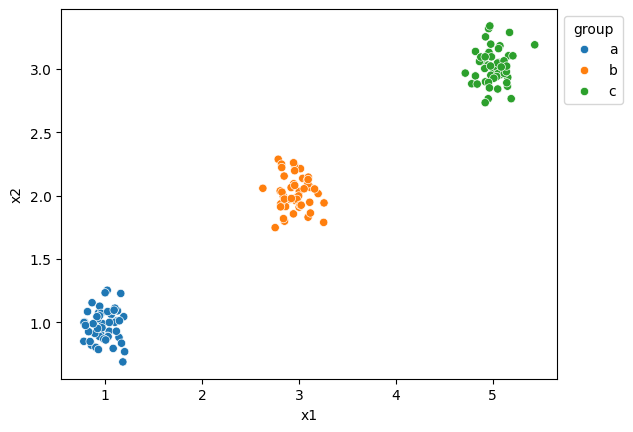

In [120]:
# Make scatterplots of the (X1, X2) points by group for each of the datasets.

# scatterplot for 0.125 dataframe
ax = sns.scatterplot(data=df0_125, x='x1', y='x2', hue='group')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

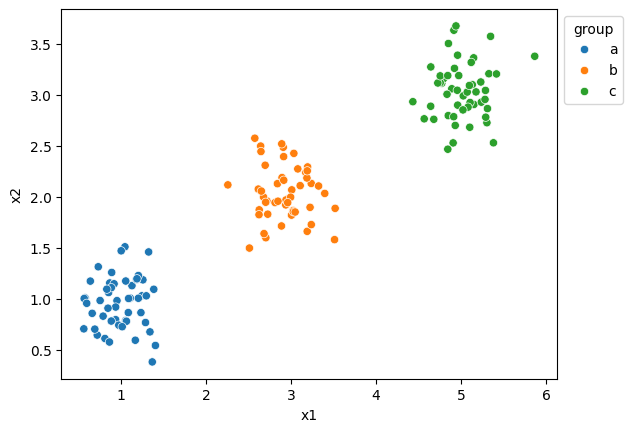

In [121]:
# scatterplot for 0.25 dataframe
ax = sns.scatterplot(data=df0_25, x='x1', y='x2', hue='group')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

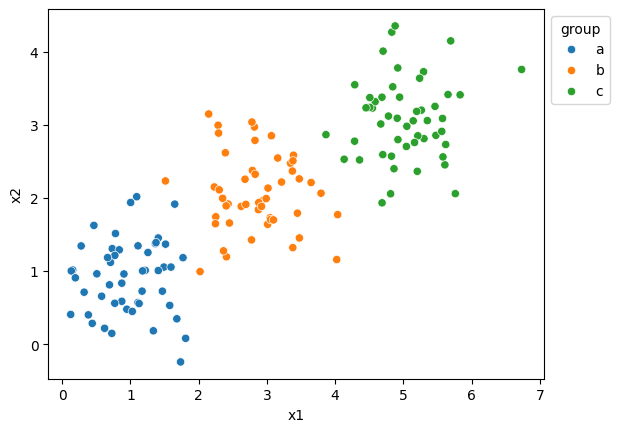

In [122]:
# scatterplot for 0.5 dataframe
ax = sns.scatterplot(data=df0_5, x='x1', y='x2', hue='group')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

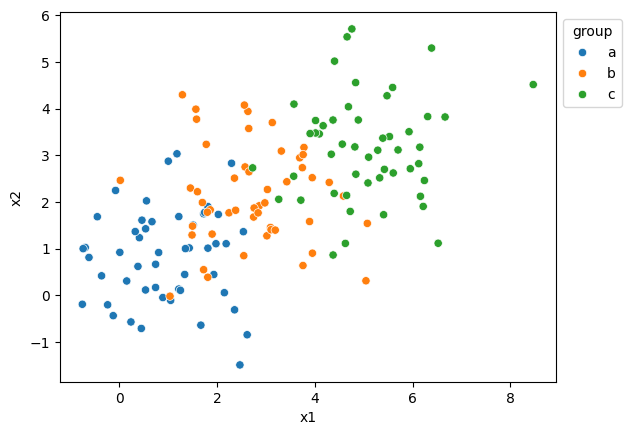

In [123]:
# scatterplot for 1.0 dataframe
ax = sns.scatterplot(data=df1_0, x='x1', y='x2', hue='group')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

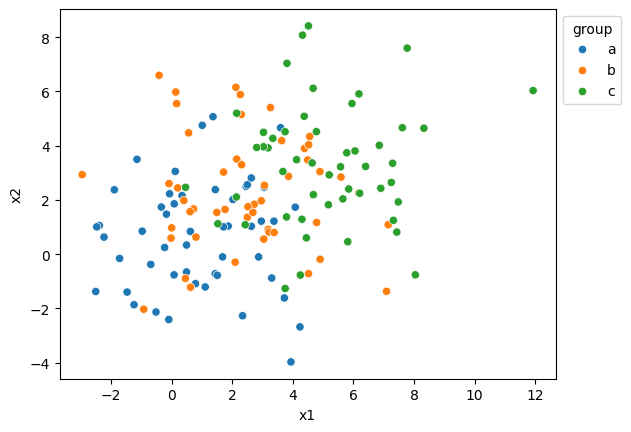

In [124]:
# scatterplot for 2.0 dataframe
ax = sns.scatterplot(data=df2_0, x='x1', y='x2', hue='group')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

Question: As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?

Answer: As the `noise` goes up from 0.125 to 2.0, the visual distinctness of the clusters get closer and closer together. The clustered points are overlapping one another as the `noise` goes up, closer to the origin.

[Text(0.5, 1.0, 'Scree Plot for 0.125'),
 Text(0.5, 0, 'k'),
 Text(0, 0.5, 'SSE')]

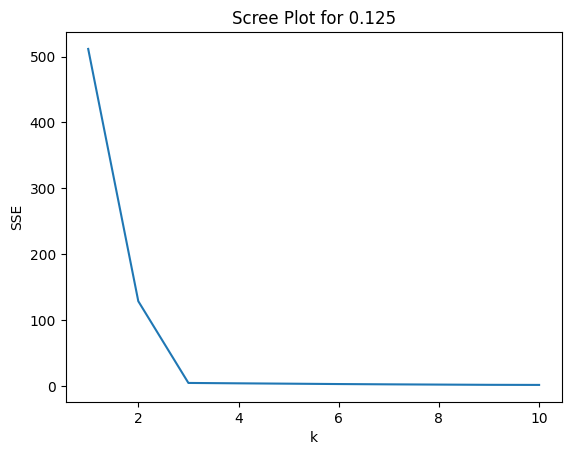

In [125]:
# Create a scree plot for each of the datasets

# Scree plot for 0.125 dataframe
X = df0_125[['x1', 'x2']]
ks = np.arange(1, 11)

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot for 0.125", xlabel="k", ylabel="SSE")

[Text(0.5, 1.0, 'Scree Plot for 0.25'), Text(0.5, 0, 'k'), Text(0, 0.5, 'SSE')]

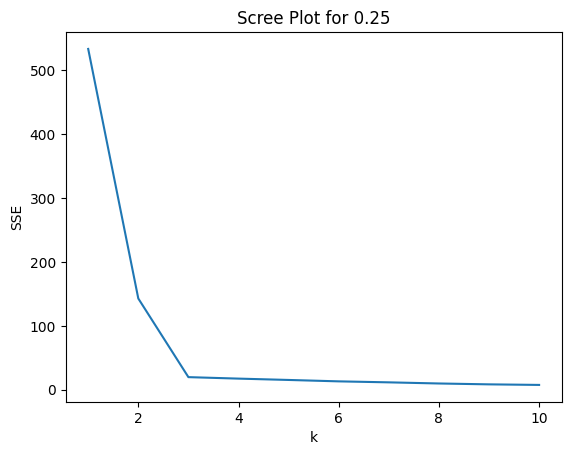

In [126]:
# Scree plot for 0.25 dataframe
X = df0_25[['x1', 'x2']]
ks = np.arange(1, 11)

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot for 0.25", xlabel="k", ylabel="SSE")

[Text(0.5, 1.0, 'Scree Plot for 0.5'), Text(0.5, 0, 'k'), Text(0, 0.5, 'SSE')]

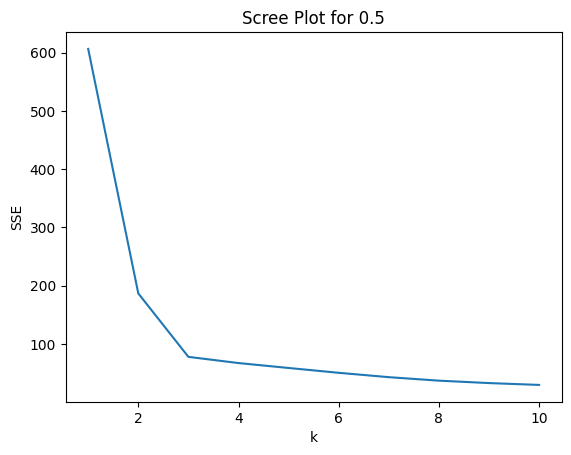

In [127]:
# Scree plot for 0.5 dataframe
X = df0_5[['x1', 'x2']]
ks = np.arange(1, 11)

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot for 0.5", xlabel="k", ylabel="SSE")

[Text(0.5, 1.0, 'Scree Plot for 1.0'), Text(0.5, 0, 'k'), Text(0, 0.5, 'SSE')]

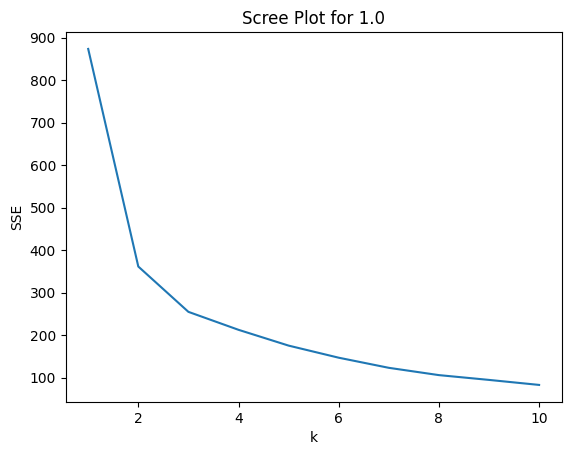

In [128]:
# Scree plot for 1.0 dataframe
X = df1_0[['x1', 'x2']]
ks = np.arange(1, 11)

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot for 1.0", xlabel="k", ylabel="SSE")

[Text(0.5, 1.0, 'Scree Plot for 2.0'), Text(0.5, 0, 'k'), Text(0, 0.5, 'SSE')]

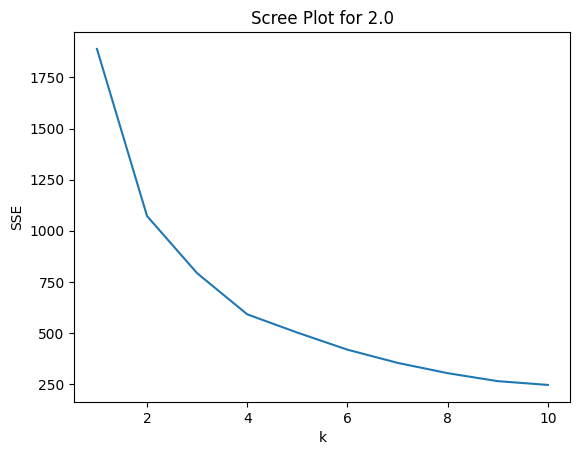

In [129]:
# Scree plot for 2.0 dataframe
X = df2_0[['x1', 'x2']]
ks = np.arange(1, 11)

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot for 2.0", xlabel="k", ylabel="SSE")

Question: Describe how the level of noise affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a  k . (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)

Answer: The level of noise affects the scree plots especially the elbow where the true k value is shown. The noise and SSE increase and decrease at the same rate. As noise increases, the rate of SSE also increases. The k value that would work for all of them would be when k is 3.

Question: Explain the intuition of the elbow, using this numerical simulation as an example.

Answer: Elbow is used to help determine the best k value which is the optimal number of clusters. As seen in the scree plots for each variation of noise, the number of clusters (k values) are consistantly 3 because it is where the graph curves. When the noise was 0.125, the graph had a sharper curve and the SSE values is up to 500 whereas when the noise was 2.0, the graph had looser curve and the SSE values when up to 1750.

In [130]:
# All of my imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Loaded the `SIPRI Military Expenditure Database.csv` from the `./data` folder.
# Saving the csv data to a pandas dataframe
df = pd.read_csv('/content/SIPRI Military Expenditure Database.csv')
df.head()

# Copy of cleaned SIPRI Military Expenditure Database from originial data set
df.to_csv('/content/SIPRI Military Expenditure Database.csv', index=False)

# Checking the dataframe contents
df

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
0,0,1988,Afghanistan,NaN,NaN,NaN,NaN
1,1,1989,Afghanistan,NaN,NaN,NaN,NaN
2,2,1990,Afghanistan,NaN,NaN,NaN,NaN
3,3,1991,Afghanistan,NaN,NaN,NaN,NaN
4,4,1992,Afghanistan,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...
5877,5877,2017,Zimbabwe,571.920778,0.003878,1.385588,23.918101
5878,5878,2018,Zimbabwe,638.310913,0.003093,1.401774,29.113096
5879,5879,2019,Zimbabwe,796.573534,0.005348,1.761478,37.346466
5880,5880,2020,Zimbabwe,8.622460,0.000054,0.018941,0.580129


In [131]:
# Filtered the rows to select only the year 2020
df = df[df['Year'] == 2020]

# Drop all rows with missing values
df = df.dropna()

# Displaying these changes
df

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731
...,...,...,...,...,...,...,...
5506,5506,2020,United Kingdom,60675.039625,0.022408,0.045629,893.778388
5540,5540,2020,United States of America,778397.200000,0.037179,0.081976,2351.631858
5574,5574,2020,Uruguay,1091.535360,0.021777,0.062082,314.201312
5846,5846,2020,Zambia,212.142427,0.011542,0.034261,11.539514


In [136]:
# Displaying these to determine whether there is further cleaning required
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
Index: 148 entries, 32 to 5880
Data columns (total 7 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   index                           148 non-null    int64  
 1   Year                            148 non-null    int64  
 2   Country                         148 non-null    object 
 3   Spending (2020 USD)             148 non-null    float64
 4   Percent of GDP                  148 non-null    float64
 5   Percent of Government Spending  148 non-null    float64
 6   Spending per Capita             148 non-null    float64
dtypes: float64(4), int64(2), object(1)
memory usage: 9.2+ KB


,index,Year,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
count,148.000000,148.0,148.000000,148.000000,148.000000,148.000000
mean,2831.256757,2020.0,13153.747670,0.019619,0.061510,268.264494
std,1654.299355,0.0,68005.236120,0.015033,0.046207,430.434878
min,32.000000,2020.0,8.622460,0.000054,0.004896,0.580129
25%,1409.000000,2020.0,204.877177,0.010413,0.031352,20.553464
50%,2871.000000,2020.0,959.535443,0.015324,0.047402,81.506703
75%,4222.500000,2020.0,5289.998320,0.024327,0.084681,326.267753
max,5880.000000,2020.0,778397.200000,0.098470,0.303027,2520.398541


Question: I ended up with 148 countries. Is any further cleaning of the variables required?

Answer: Yes, the indexes for each entry in the dataframe must be fixed so that it matches the physical location of where it is stored in the updated dataframe. It will make it easier understandable and accessible now that the data has been cleaned.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [134]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]